# Bài tập 6 — Mở rộng SARIMA với AirPassengers

> **Trạng thái:** E6 là phần mở rộng `EXPLORATORY`, độc lập với phạm vi chính thức E1–E5. Residual diagnostics đã được sửa và kiểm chứng, nhưng E6 không được đánh dấu hoàn thành chính thức.

## Tổng quan 5W1H

| Thành phần | Nội dung |
|---|---|
| **What — Làm gì?** | So sánh ARIMA với SARIMA trên AirPassengers và kiểm tra tác động của seasonal modeling. |
| **Why — Vì sao?** | Đánh giá liệu seasonal component chu kỳ 12 có cải thiện forecast và residual diagnostics so với ARIMA không mùa vụ hay không. |
| **Who — Dành cho ai?** | Người học và người review muốn xem phần mở rộng SARIMA tách biệt khỏi E1–E5. |
| **When — Khi nào?** | Dữ liệu tháng từ 1949-01 đến 1960-12, chia chronological train/test 80/20. |
| **Where — Thực hiện ở đâu?** | Advanced notebook E6, dùng `datasets/raw/airline-passengers.csv`; residual artifact nằm trong `outputs/`. |
| **How — Thực hiện thế nào?** | Validate dữ liệu → log scale → ADF/differencing → ACF/PACF → fit ARIMA/SARIMA → residual diagnostics → forecast và MAE/RMSE. |

## Nguồn dữ liệu

- Dataset theo đề bài: [AirPassengers (`airline-passengers.csv`)](https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv).

## 1. Dữ liệu và holdout riêng

- Dữ liệu: AirPassengers theo tháng, từ 01/1949 đến 12/1960.
- Chia theo thời gian: 80% huấn luyện và 20% kiểm tra, không xáo trộn.
- Mọi quyết định về thang đo, sai phân và bậc mô hình chỉ dùng tập huấn luyện.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display

PROJECT_ROOT = next(
    (root for root in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (root / "datasets" / "raw" / "airline-passengers.csv").is_file()),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Practice_2 project containing datasets/raw/airline-passengers.csv was not found."
    )

AIRPASSENGERS_PATH = PROJECT_ROOT / "datasets" / "raw" / "airline-passengers.csv"
TABLE_THEME_PATH = PROJECT_ROOT / "notebooks" / "styles" / "table_theme.css"
display(HTML(f'<style>{TABLE_THEME_PATH.read_text(encoding="utf-8")}</style>'))

print("Project root:", PROJECT_ROOT)
print("AirPassengers dataset:", AIRPASSENGERS_PATH)

Project root: /Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_2
AirPassengers dataset: /Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_2/datasets/raw/airline-passengers.csv


In [2]:
air_df = pd.read_csv(AIRPASSENGERS_PATH)

if list(air_df.columns) != ["Month", "Passengers"]:
    raise ValueError(f"Schema does not match the approved contract: {air_df.columns.tolist()}")

air_df["Month"] = pd.to_datetime(
    air_df["Month"],
    format="%Y-%m",
    errors="raise",
)
air_df["Passengers"] = pd.to_numeric(air_df["Passengers"], errors="raise")
air_df = air_df.set_index("Month")

if not air_df.index.is_monotonic_increasing:
    raise ValueError("Datetime index is not in chronological order.")
if air_df.index.has_duplicates:
    raise ValueError("Duplicate timestamps were detected.")
if air_df["Passengers"].isna().any():
    raise ValueError("Target contains missing values.")

expected_index = pd.date_range(
    start="1949-01-01",
    end="1960-12-01",
    freq="MS",
)

if len(air_df) != 144 or not air_df.index.equals(expected_index):
    raise ValueError("Row count, date range, or monthly frequency violates the contract.")

air_series = air_df["Passengers"].astype(float)
air_series.index = pd.DatetimeIndex(air_series.index, freq="MS", name="Month")

split_at = int(len(air_series) * 0.8)
air_train = air_series.iloc[:split_at].copy()
air_test = air_series.iloc[split_at:].copy()

if len(air_train) != 115 or len(air_test) != 29:
    raise ValueError(
        f"Split violates the contract: train={len(air_train)}, test={len(air_test)}"
    )
if air_train.index.max() >= air_test.index.min():
    raise ValueError("Train/test boundary does not preserve chronological order.")

print(f"Rows: {len(air_series)}")
print(f"Train: {len(air_train)} ({air_train.index.min():%Y-%m} to {air_train.index.max():%Y-%m})")
print(f"Test: {len(air_test)} ({air_test.index.min():%Y-%m} to {air_test.index.max():%Y-%m})")
print("Split: chronological 80/20, shuffle=False")

Rows: 144
Train: 115 (1949-01 to 1958-07)
Test: 29 (1958-08 to 1960-12)
Split: chronological 80/20, shuffle=False


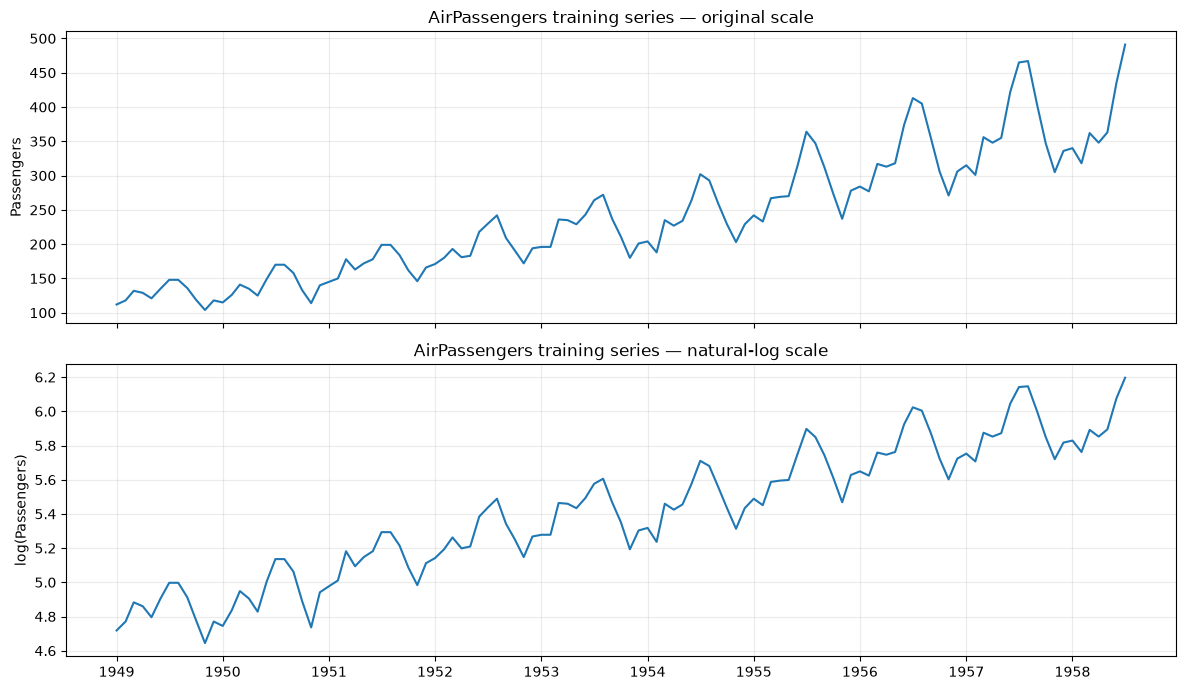

In [3]:
import matplotlib.pyplot as plt

if (air_train <= 0).any():
    raise ValueError("Log scale cannot be evaluated because training contains non-positive values.")

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(air_train.index, air_train)
axes[0].set_title("AirPassengers training series — original scale")
axes[0].set_ylabel("Passengers")
axes[0].grid(alpha=0.25)

axes[1].plot(air_train.index, np.log(air_train))
axes[1].set_title("AirPassengers training series — natural-log scale")
axes[1].set_ylabel("log(Passengers)")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

#### Nhận diện mùa vụ và lựa chọn thang đo

Chuỗi huấn luyện có xu hướng tăng, mùa vụ 12 tháng và biên độ dao động tăng theo mức chuỗi. Vì vậy, sử dụng log tự nhiên để ổn định phương sai; tập kiểm tra không tham gia quyết định này.

## 2. Tính dừng và sai phân

#### Kiểm định ADF trên chuỗi huấn luyện ở thang log

In [4]:
from statsmodels.tsa.stattools import adfuller

ANALYSIS_SCALE = "log"
ADF_ALPHA = 0.05

if ANALYSIS_SCALE == "log":
    air_train_analysis = np.log(air_train)
else:
    air_train_analysis = air_train.copy()

adf_result = adfuller(
    air_train_analysis,
    regression="c",
    autolag="AIC",
)

adf_statistic, adf_pvalue, used_lag, nobs, critical_values = adf_result[:5]
adf_decision = (
    "reject H0"
    if adf_pvalue <= ADF_ALPHA
    else "fail to reject H0"
)

print(f"Scale: {ANALYSIS_SCALE}")
print("H0: the series has a unit root.")
print(f"ADF statistic: {adf_statistic:.6f}")
print(f"p-value: {adf_pvalue:.6g}")
print(f"Used lag: {used_lag}")
print(f"N observations: {nobs}")
print(f"Critical values: {critical_values}")
print(f"Decision at alpha={ADF_ALPHA}: {adf_decision}")

Scale: log
H0: the series has a unit root.
ADF statistic: -1.574027
p-value: 0.496626
Used lag: 13
N observations: 101
Critical values: {'1%': np.float64(-3.4968181663902103), '5%': np.float64(-2.8906107514600103), '10%': np.float64(-2.5822770483285953)}
Decision at alpha=0.05: fail to reject H0


/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_26764/3975538333.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(


#### So sánh sai phân thường và sai phân mùa vụ

In [5]:
difference_variants = {
    "original": air_train_analysis,
    "regular_d1": air_train_analysis.diff(1).dropna(),
    "seasonal_D1_s12": air_train_analysis.diff(12).dropna(),
    "combined_d1_D1_s12": air_train_analysis.diff(1).diff(12).dropna(),
}

difference_rows = []

for variant_name, variant_series in difference_variants.items():
    result = adfuller(
        variant_series,
        regression="c",
        autolag="AIC",
    )

    difference_rows.append({
        "series": variant_name,
        "observations": len(variant_series),
        "ADF_statistic": result[0],
        "p_value": result[1],
        "used_lag": result[2],
        "n_observations": result[3],
        "decision_at_0.05": (
            "reject H0" if result[1] <= ADF_ALPHA else "fail to reject H0"
        ),
    })

difference_results = pd.DataFrame(difference_rows)
display(Markdown('**So sánh ADF giữa các phương án differencing**'))
display(difference_results)

/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_26764/2039165437.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_26764/2039165437.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_26764/2039165437.py

**So sánh ADF giữa các phương án differencing**

,series,observations,ADF_statistic,p_value,used_lag,n_observations,decision_at_0.05
0,original,115,-1.574027,0.496626,13,101,fail to reject H0
1,regular_d1,114,-2.635851,0.085812,12,101,fail to reject H0
2,seasonal_D1_s12,103,-1.991013,0.290527,12,90,fail to reject H0
3,combined_d1_D1_s12,102,-3.946340,0.001719,11,90,reject H0


#### Kết quả kiểm định tính dừng

- Chuỗi log ban đầu, sai phân thường riêng và sai phân mùa vụ riêng đều có `p-value > 0.05`.
- Kết hợp `d=1`, `D=1`, `s=12` cho ADF statistic `-3.946340`, p-value `0.001719`.
- Kết quả hỗ trợ tính dừng của chuỗi huấn luyện đã biến đổi; tập kiểm tra chưa được sử dụng.

#### Chuỗi huấn luyện dùng cho ACF/PACF

Selected d=1, D=1, s=12
Transformed observations: 102
First timestamp: 1950-02-01 00:00:00
Last timestamp: 1958-07-01 00:00:00


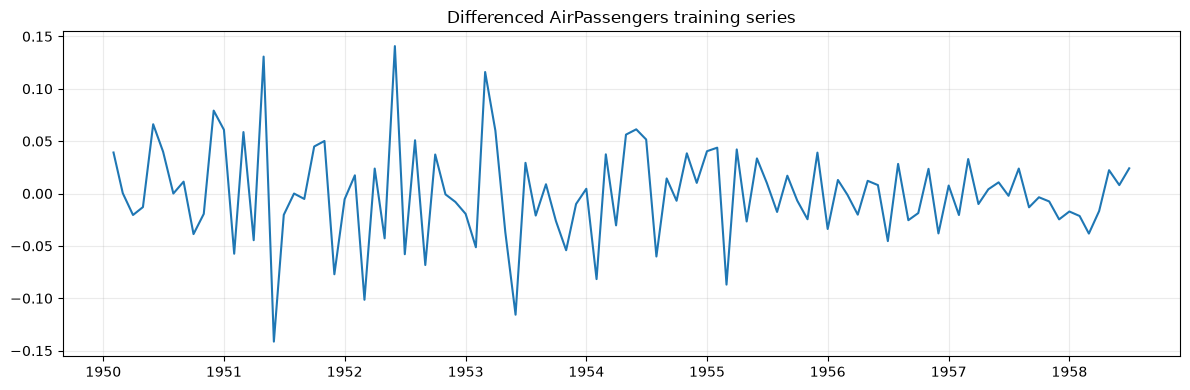

In [6]:
SELECTED_D = 1
SELECTED_D_SEASONAL = 1
SEASONAL_PERIOD = 12

stationary_train = air_train_analysis.copy()

for _ in range(SELECTED_D):
    stationary_train = stationary_train.diff(1)

for _ in range(SELECTED_D_SEASONAL):
    stationary_train = stationary_train.diff(SEASONAL_PERIOD)

stationary_train = stationary_train.dropna()

if stationary_train.isna().any() or stationary_train.empty:
    raise ValueError("Differenced series is empty or still contains missing values.")

print(f"Selected d={SELECTED_D}, D={SELECTED_D_SEASONAL}, s={SEASONAL_PERIOD}")
print(f"Transformed observations: {len(stationary_train)}")
print(f"First timestamp: {stationary_train.index.min()}")
print(f"Last timestamp: {stationary_train.index.max()}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(stationary_train.index, stationary_train)
ax.set_title("Differenced AirPassengers training series")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 3. ACF/PACF và đề xuất mô hình ứng viên

/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_26764/812781402.py:7: FutureWarning: acf currently returns a plain tuple whose length depends on the qstat and alpha arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an AcfResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  acf_values, acf_confint = acf(


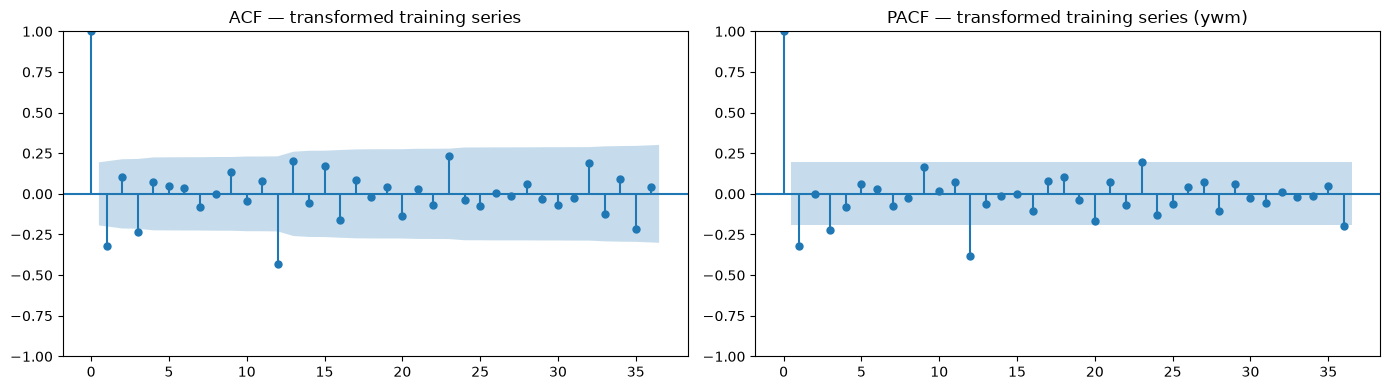

**Các ACF lags có ý nghĩa thống kê, không gồm lag 0**

,lag,correlation,ci_lower,ci_upper,significant
1,1,-0.320677,-0.514743,-0.126612,True
3,3,-0.232934,-0.447858,-0.018010,True
12,12,-0.429978,-0.661059,-0.198898,True


**Các PACF lags có ý nghĩa thống kê, không gồm lag 0**

,lag,correlation,ci_lower,ci_upper,significant
1,1,-0.320677,-0.514743,-0.126612,True
3,3,-0.223399,-0.417464,-0.029334,True
12,12,-0.383332,-0.577397,-0.189266,True
23,23,0.195020,0.000955,0.389085,True
36,36,-0.195495,-0.389561,-0.001430,True


**ACF tại các seasonal lags tham chiếu**

,lag,correlation,ci_lower,ci_upper,significant
12,12,-0.429978,-0.661059,-0.198898,True
24,24,-0.038973,-0.324378,0.246432,False
36,36,0.044010,-0.257094,0.345114,False


**PACF tại các seasonal lags tham chiếu**

,lag,correlation,ci_lower,ci_upper,significant
12,12,-0.383332,-0.577397,-0.189266,True
24,24,-0.130721,-0.324787,0.063344,False
36,36,-0.195495,-0.389561,-0.001430,True


In [7]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf

if len(stationary_train) <= 36:
    raise ValueError("Insufficient observations to compute through lag 36.")

acf_values, acf_confint = acf(
    stationary_train,
    nlags=36,
    alpha=0.05,
    fft=False,
)
pacf_values, pacf_confint = pacf(
    stationary_train,
    nlags=36,
    alpha=0.05,
    method="ywm",
)

acf_table = pd.DataFrame({
    "lag": np.arange(len(acf_values)),
    "correlation": acf_values,
    "ci_lower": acf_confint[:, 0],
    "ci_upper": acf_confint[:, 1],
})
acf_table["significant"] = (
    (acf_table["ci_lower"] > 0) | (acf_table["ci_upper"] < 0)
)

pacf_table = pd.DataFrame({
    "lag": np.arange(len(pacf_values)),
    "correlation": pacf_values,
    "ci_lower": pacf_confint[:, 0],
    "ci_upper": pacf_confint[:, 1],
})
pacf_table["significant"] = (
    (pacf_table["ci_lower"] > 0) | (pacf_table["ci_upper"] < 0)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(stationary_train, lags=36, alpha=0.05, ax=axes[0])
plot_pacf(stationary_train, lags=36, alpha=0.05, method="ywm", ax=axes[1])
axes[0].set_title("ACF — transformed training series")
axes[1].set_title("PACF — transformed training series (ywm)")
plt.tight_layout()
plt.show()

display(Markdown('**Các ACF lags có ý nghĩa thống kê, không gồm lag 0**'))
display(acf_table.loc[(acf_table["lag"] > 0) & acf_table["significant"]])

display(Markdown('**Các PACF lags có ý nghĩa thống kê, không gồm lag 0**'))
display(pacf_table.loc[(pacf_table["lag"] > 0) & pacf_table["significant"]])

display(Markdown('**ACF tại các seasonal lags tham chiếu**'))
display(
    acf_table.loc[acf_table["lag"].isin([12, 24, 36])],
)
display(Markdown('**PACF tại các seasonal lags tham chiếu**'))
display(
    pacf_table.loc[pacf_table["lag"].isin([12, 24, 36])],
)

#### Mô hình ứng viên từ ACF/PACF

ACF/PACF của chuỗi huấn luyện đã sai phân kết hợp cho thấy tín hiệu đáng kể tại lag ngắn và lag mùa vụ 12. Đồ thị không xác định duy nhất bậc mô hình, nên chọn hai mô hình để kiểm tra:

- **ARIMA nền:** `ARIMA(1,1,1)`.
- **SARIMA ứng viên:** `SARIMA(1,1,1)(0,1,1,12)`.

Hai mô hình giữ cùng cấu trúc phi mùa vụ; SARIMA bổ sung thành phần MA mùa vụ với chu kỳ 12 tháng.

## 4. Ước lượng mô hình và chẩn đoán phần dư

Hai mô hình được ước lượng trên cùng tập huấn luyện ở thang log.

In [8]:
import warnings

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

p = 1
q = 1
P = 0
Q = 1

arima_order = (p, SELECTED_D, q)
sarima_order = (p, SELECTED_D, q)
sarima_seasonal_order = (P, SELECTED_D_SEASONAL, Q, SEASONAL_PERIOD)

if ANALYSIS_SCALE == "log":
    train_model = np.log(air_train)
else:
    train_model = air_train.copy()

model_specs = {
    "ARIMA": lambda: ARIMA(train_model, order=arima_order).fit(),
    "SARIMA": lambda: SARIMAX(
        train_model,
        order=sarima_order,
        seasonal_order=sarima_seasonal_order,
    ).fit(disp=False),
}

fitted_models = {}
fit_rows = []

for model_name, fit_function in model_specs.items():
    with warnings.catch_warnings(record=True) as caught_warnings:
        warnings.simplefilter("always")
        fitted = fit_function()

    fitted_models[model_name] = fitted
    mle_info = getattr(fitted, "mle_retvals", {})

    fit_rows.append({
        "model": model_name,
        "order": arima_order if model_name == "ARIMA" else sarima_order,
        "seasonal_order": None if model_name == "ARIMA" else sarima_seasonal_order,
        "converged": mle_info.get("converged"),
        "AIC": fitted.aic,
        "BIC": fitted.bic,
        "warnings": " | ".join(str(item.message) for item in caught_warnings),
    })

fit_results = pd.DataFrame(fit_rows)
fit_classes = pd.DataFrame('', index=fit_results.index, columns=fit_results.columns)
for criterion_name in ['AIC', 'BIC']:
    fit_classes.loc[fit_results[criterion_name].idxmin(), criterion_name] = 'metric-best'
fit_view = (
    fit_results.style
    .format({'AIC': '{:.3f}', 'BIC': '{:.3f}'})
    .set_td_classes(fit_classes)
    .set_table_attributes('class="dataframe practice2-table"')
)
display(Markdown('**Kết quả fitting — ô xanh là information criterion tốt nhất**'))
display(fit_view)

**Kết quả fitting — ô xanh là information criterion tốt nhất**

,model,order,seasonal_order,converged,AIC,BIC,warnings
0,ARIMA,"(1, 1, 1)",None,True,-197.221,-189.013,
1,SARIMA,"(1, 1, 1)","(0, 1, 1, 12)",True,-369.862,-359.363,


#### Chẩn đoán phần dư sau giai đoạn khởi tạo

**Residual diagnostics của ARIMA và SARIMA**

,model,residual_mean,residual_observations,burn_in,lag,model_df,alpha,lb_stat,lb_pvalue,reject_no_autocorrelation,white_noise_supported
0,ARIMA,0.011221,114,1,12,2,0.05,96.333346,2.944816e-16,True,False
1,ARIMA,0.011221,114,1,24,2,0.05,183.014687,2.308263e-27,True,False
2,SARIMA,0.001164,102,13,12,3,0.05,7.608826,5.739958e-01,False,True
3,SARIMA,0.001164,102,13,24,3,0.05,20.762224,4.735451e-01,False,True


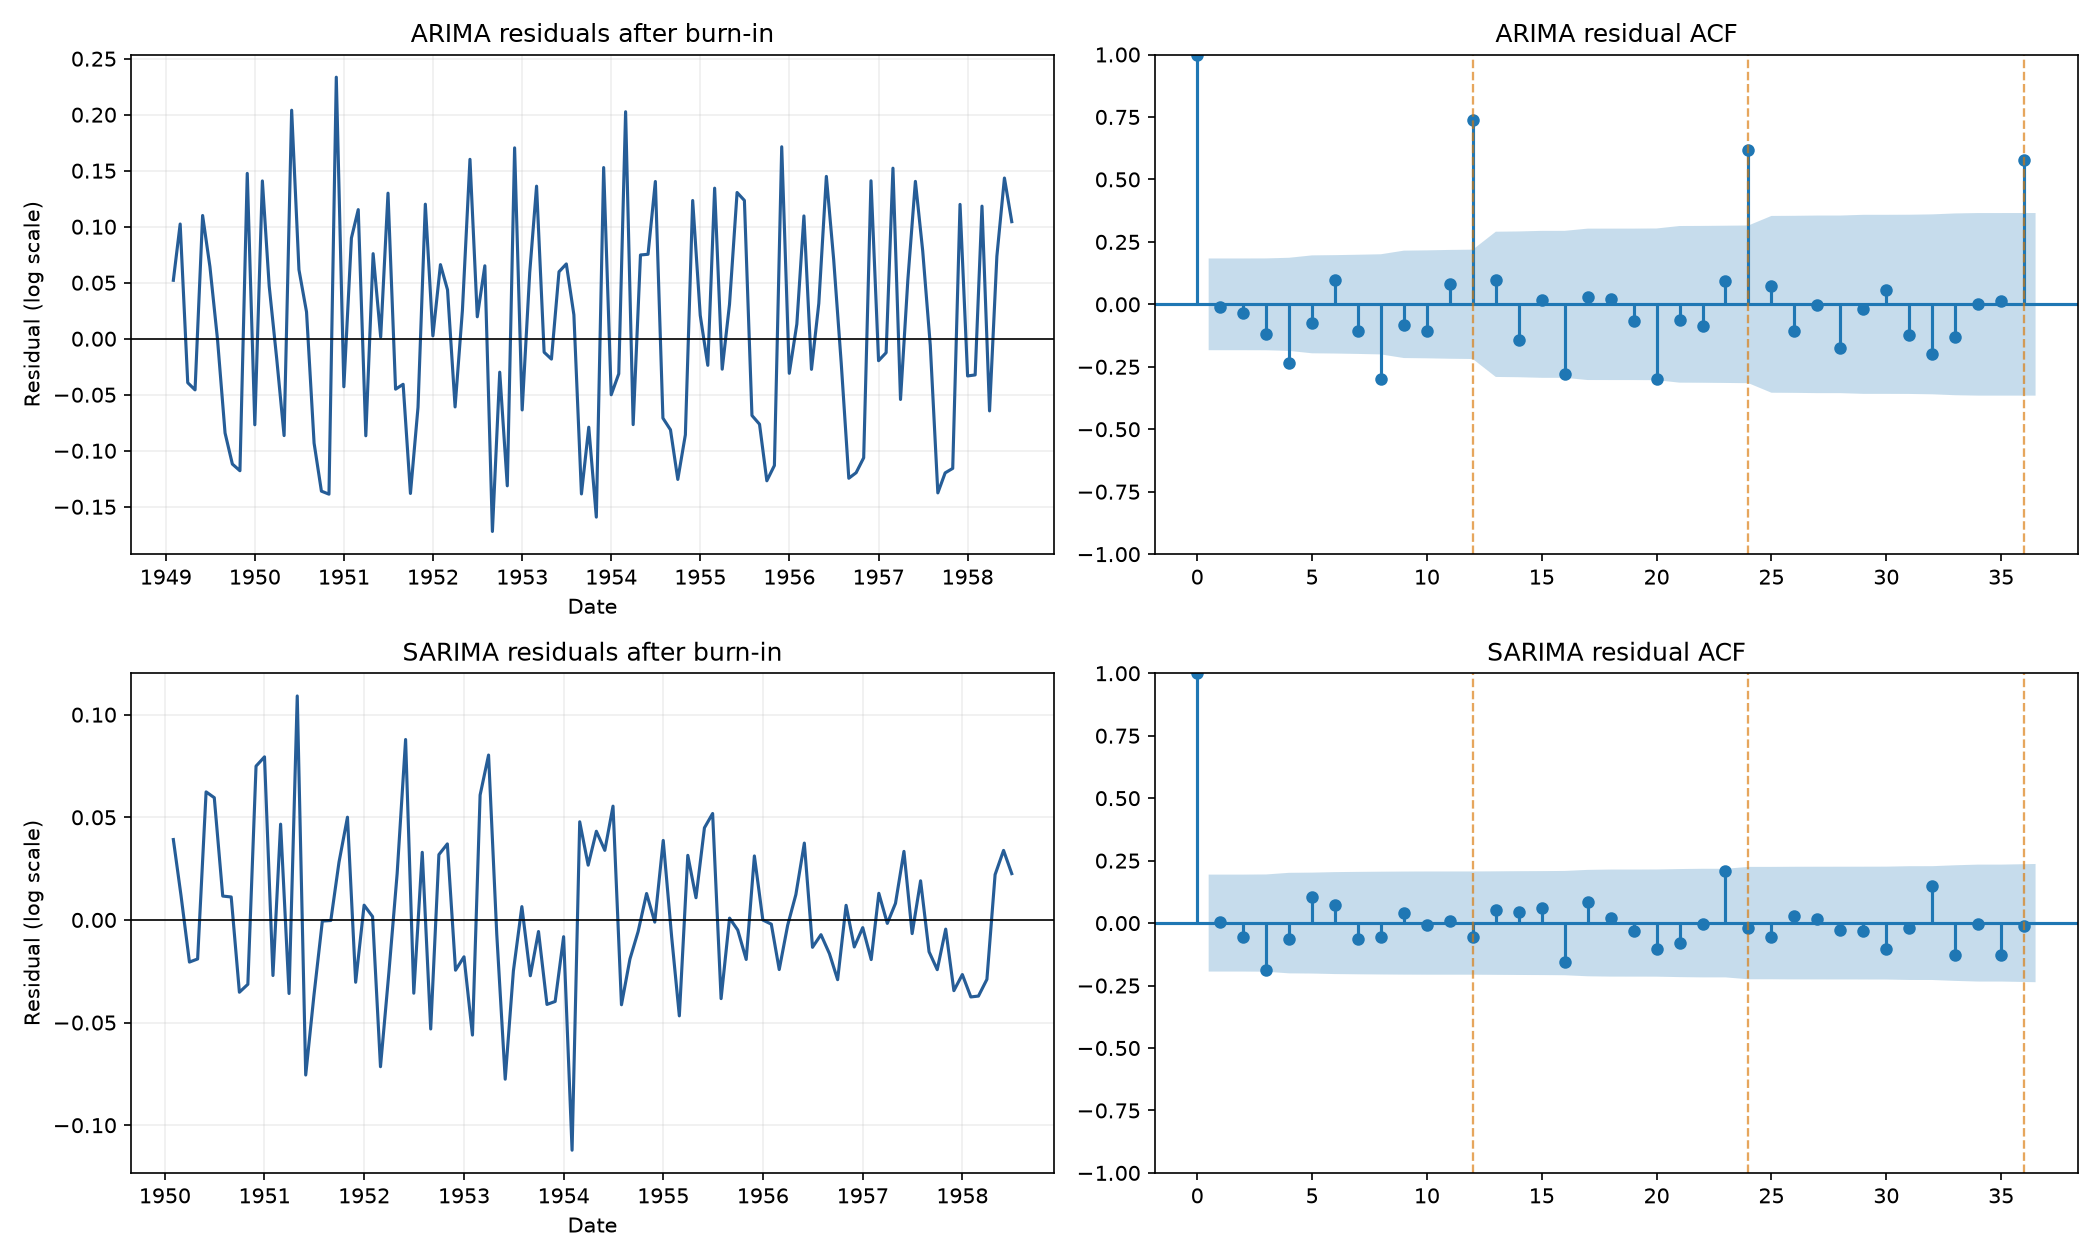

In [9]:
from IPython.display import Image

from practice_2.analysis import compute_residual_diagnostics
from practice_2.visualization.plots import save_residual_diagnostics_plot

residuals_by_model, residual_diagnostics = compute_residual_diagnostics(
    fitted_models,
    lags=(12, 24),
    alpha=0.05,
)

residual_output_path = (
    PROJECT_ROOT / "outputs" / "results" / "06_airpassengers_model_diagnostics.csv"
)
residual_figure_path = (
    PROJECT_ROOT / "outputs" / "figures" / "06_airpassengers_residual_diagnostics.png"
)

residual_output_path.parent.mkdir(parents=True, exist_ok=True)
residual_diagnostics.to_csv(residual_output_path, index=False)
save_residual_diagnostics_plot(
    residuals_by_model,
    residual_figure_path,
    nlags=36,
    alpha=0.05,
)

display(Markdown('**Residual diagnostics của ARIMA và SARIMA**'))
display(residual_diagnostics)
display(Image(filename=str(residual_figure_path)))

#### Kết quả phần dư

- **ARIMA:** còn tự tương quan tại lag 12 và 24.
- **SARIMA:** chưa phát hiện tự tương quan tại lag 12 và 24.
- Kết quả SARIMA chỉ áp dụng cho các lag đã kiểm định; không chứng minh phần dư hoàn toàn là nhiễu trắng.

## 5. Dự báo và đánh giá trên tập kiểm tra

**So sánh forecast metrics — ô xanh là giá trị tốt nhất**

,model,MAE,RMSE
0,ARIMA,84.254,96.327
1,SARIMA,12.165,14.917


**Sai số tuyệt đối lớn nhất của từng mô hình**

,model,date,actual,forecast,absolute_error
0,ARIMA,1958-11-01,310.0,496.107318,186.107318
1,SARIMA,1960-03-01,419.0,452.013766,33.013766


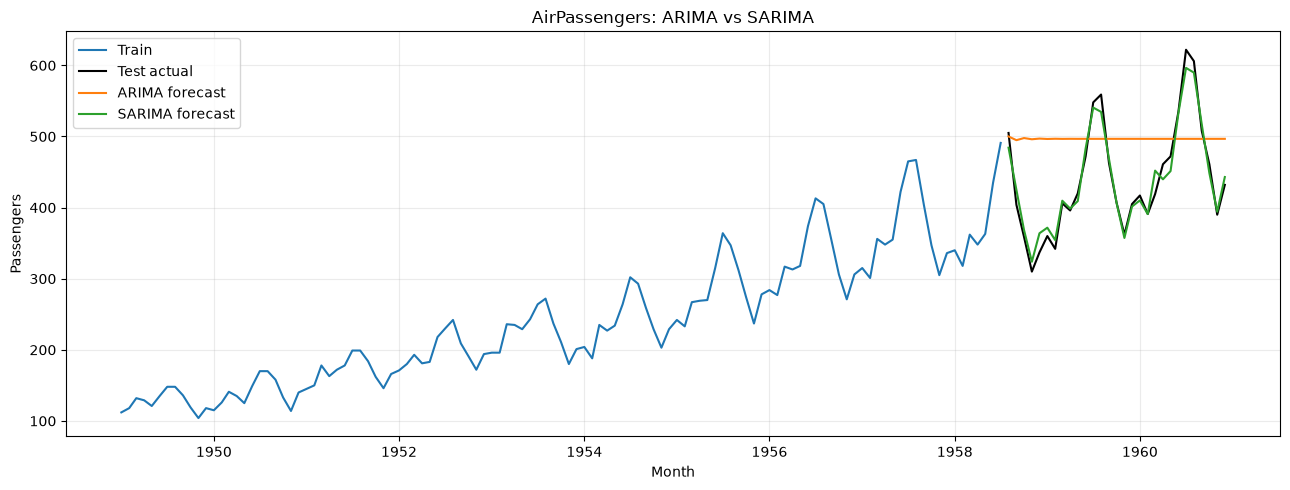

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

forecast_series = {}

for model_name, fitted in fitted_models.items():
    forecast = fitted.get_forecast(steps=len(air_test)).predicted_mean

    if len(forecast) != len(air_test):
        raise ValueError(f"{model_name}: forecast length does not match test length.")
    if not forecast.index.equals(air_test.index):
        raise ValueError(f"{model_name}: forecast index does not match test index.")

    forecast_values = np.asarray(forecast, dtype=float)

    if ANALYSIS_SCALE == "log":
        forecast_values = np.exp(forecast_values)

    forecast_series[model_name] = pd.Series(
        forecast_values,
        index=air_test.index,
        name=f"{model_name}_forecast",
    )

metric_rows = []
error_rows = []

for model_name, forecast in forecast_series.items():
    errors = air_test - forecast

    metric_rows.append({
        "model": model_name,
        "MAE": mean_absolute_error(air_test, forecast),
        "RMSE": np.sqrt(mean_squared_error(air_test, forecast)),
    })

    largest_error_date = errors.abs().idxmax()
    error_rows.append({
        "model": model_name,
        "date": largest_error_date,
        "actual": air_test.loc[largest_error_date],
        "forecast": forecast.loc[largest_error_date],
        "absolute_error": abs(errors.loc[largest_error_date]),
    })

metrics_comparison = pd.DataFrame(metric_rows)
largest_errors = pd.DataFrame(error_rows)
metric_classes = pd.DataFrame('', index=metrics_comparison.index, columns=metrics_comparison.columns)
for metric_name in ['MAE', 'RMSE']:
    metric_classes.loc[metrics_comparison[metric_name].idxmin(), metric_name] = 'metric-best'
metrics_view = (
    metrics_comparison.style
    .format({'MAE': '{:.3f}', 'RMSE': '{:.3f}'})
    .set_td_classes(metric_classes)
    .set_table_attributes('class="dataframe practice2-table"')
)

display(Markdown('**So sánh forecast metrics — ô xanh là giá trị tốt nhất**'))
display(metrics_view)
display(Markdown('**Sai số tuyệt đối lớn nhất của từng mô hình**'))
display(largest_errors)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(air_train.index, air_train, label="Train")
ax.plot(air_test.index, air_test, label="Test actual", color="black")
for model_name, forecast in forecast_series.items():
    ax.plot(forecast.index, forecast, label=f"{model_name} forecast")

ax.set_title("AirPassengers: ARIMA vs SARIMA")
ax.set_xlabel("Month")
ax.set_ylabel("Passengers")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

#### So sánh ARIMA và SARIMA

| Mô hình | MAE | RMSE |
|---|---:|---:|
| ARIMA(1,1,1) | 84.254 | 96.327 |
| SARIMA(1,1,1)(0,1,1,12) | 12.165 | 14.917 |

SARIMA có MAE và RMSE thấp hơn ARIMA trên cùng 29 tháng kiểm tra. Đường dự báo SARIMA theo sát cấu trúc mùa vụ tốt hơn, trong khi dự báo ARIMA gần như phẳng.

## 6. Kết luận E6

- AirPassengers có xu hướng tăng và mùa vụ 12 tháng rõ rệt.
- Chuỗi log chỉ đạt bằng chứng dừng sau khi kết hợp `d=1`, `D=1`, `s=12`.
- Trên holdout hiện tại, SARIMA có MAE/RMSE thấp hơn ARIMA nền.
- ARIMA còn tự tương quan tại lag 12/24; SARIMA chưa cho thấy tự tương quan tại hai lag này sau khi loại giai đoạn khởi tạo.
- Kết luận chỉ áp dụng cho dataset, cách chia dữ liệu và hai cấu hình mô hình đang xét; E6 vẫn chờ Human review cuối.